# 3. Team season: what separates the table?

**Questions**
1. How well do underlying numbers (xG and xT differentials) explain where teams finished?
2. Which teams over- or under-performed their underlying numbers?
3. What playing styles appear when teams are described by how they create and concede threat?

**A note on sample size.** A season has 20 teams. With n = 20, an 80/20 train/test split leaves 4 teams to evaluate on, which is far too few. Every model here is evaluated with **leave-one-out cross-validation** (each team predicted by a model fitted on the other 19), and models are limited to one or two predictors.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import LeaveOneOut, cross_val_predict
from sklearn.preprocessing import StandardScaler

from epl_xt import config
from epl_xt.plotting import (DIVERGING, MUTED, SERIES, SURFACE, TEXT_SECONDARY, apply_style, label_points,
                             save, short_team)

apply_style()
pd.set_option("display.precision", 2)

teams = pd.read_parquet(config.TEAM_SEASON_TABLE)
teams["short"] = teams["team"].map(short_team)
table_cols = ["rank", "team", "wins", "draws", "losses", "goals_for", "goals_against", "points",
              "npxg", "npxg_against", "npxg_diff", "xt", "xt_against", "xt_diff"]
teams[table_cols]

,rank,team,wins,draws,losses,goals_for,goals_against,points,npxg,npxg_against,npxg_diff,xt,xt_against,xt_diff
0,1,Leicester City,23,12,3,68,36,81,56.10,43.00,13.10,40.48,44.75,-4.28
1,2,Arsenal,20,11,7,65,36,71,63.52,32.79,30.73,56.76,35.15,21.61
2,3,Tottenham Hotspur,19,13,6,69,35,70,58.44,33.99,24.44,44.32,31.90,12.41
3,4,Manchester City,19,9,10,71,41,66,58.29,38.28,20.01,47.60,28.17,19.43
4,5,Manchester United,19,9,10,49,35,66,39.85,36.95,2.90,42.77,31.86,10.91
5,6,Southampton,18,9,11,59,41,63,51.09,38.97,12.12,42.50,36.23,6.27
6,7,West Ham United,16,14,8,65,51,62,51.39,48.00,3.39,37.69,40.74,-3.06
7,8,Liverpool,16,12,10,63,50,60,56.81,35.68,21.13,49.72,30.12,19.59
8,9,Stoke City,14,9,15,41,55,51,36.45,51.32,-14.87,33.89,42.14,-8.25
9,10,Chelsea,12,14,12,59,53,50,49.66,44.83,4.83,47.33,35.86,11.47


The table matches the official 2015/16 final standings: Leicester first on 81 points and Aston Villa last on 17, with 1,026 goals in total. Scores come from the match results, so own goals are included.

## Q1. Points vs. underlying numbers

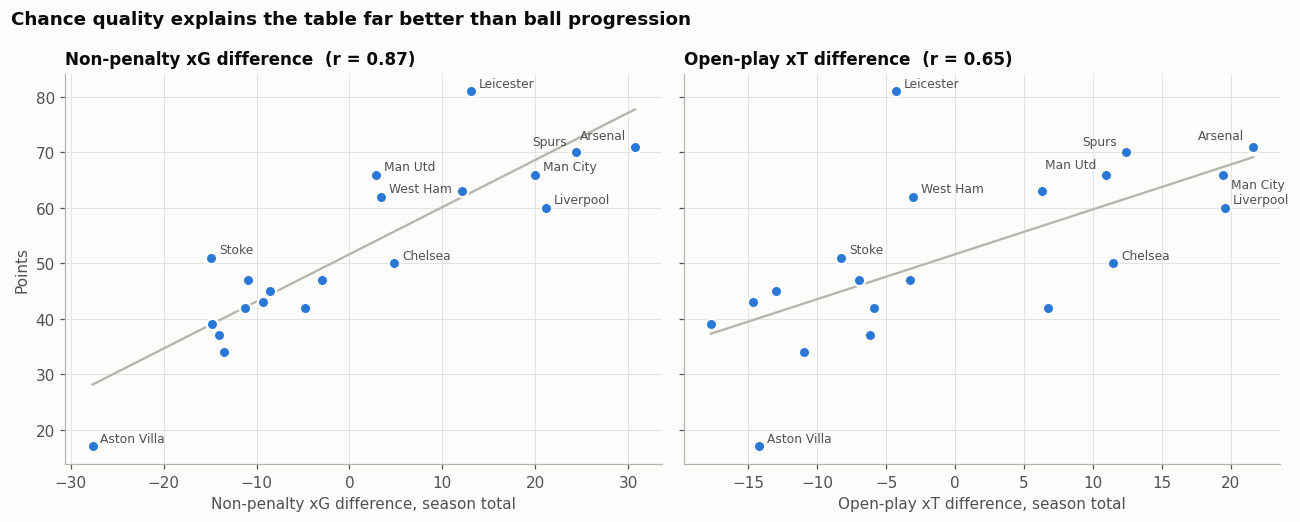

In [2]:
LABEL = ["Leicester", "Arsenal", "Spurs", "Man City", "Man Utd", "Liverpool", "Chelsea", "Aston Villa",
         "West Ham", "Stoke"]
OFFSETS = {
    "npxg_diff": {"Arsenal": (-6, 5), "Spurs": (-6, 5)},
    "xt_diff": {"Arsenal": (-6, 5), "Man Utd": (-6, 4), "Man City": (5, -9), "Spurs": (-6, 5)},
}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
for ax, col, title in [(axes[0], "npxg_diff", "Non-penalty xG difference"),
                       (axes[1], "xt_diff", "Open-play xT difference")]:
    fit = np.polyfit(teams[col], teams["points"], 1)
    xs = np.linspace(teams[col].min(), teams[col].max(), 50)
    ax.plot(xs, np.polyval(fit, xs), color=MUTED, lw=1.5, zorder=1)
    ax.scatter(teams[col], teams["points"], s=55, color=SERIES[0], edgecolor=SURFACE, linewidth=1.5, zorder=2)
    shown = teams[teams["short"].isin(LABEL)]
    label_points(ax, shown[col], shown["points"], shown["short"], OFFSETS[col])
    r = np.corrcoef(teams[col], teams["points"])[0, 1]
    ax.set_title(f"{title}  (r = {r:.2f})", fontsize=11)
    ax.set_xlabel(f"{title}, season total")
axes[0].set_ylabel("Points")
fig.suptitle("Chance quality explains the table far better than ball progression",
             x=0.01, ha="left", fontweight="semibold")
fig.tight_layout()
save(fig, "team_points_vs_underlying")
plt.show()

In [3]:
loo = LeaveOneOut()
candidates = {
    "goal_diff (reference)": ["goal_diff"],
    "npxg_diff": ["npxg_diff"],
    "xt_diff": ["xt_diff"],
    "npxg_diff + xt_diff": ["npxg_diff", "xt_diff"],
    "npxg_for + npxg_against": ["npxg", "npxg_against"],
    "xt_for + xt_against": ["xt", "xt_against"],
}
rows, preds = [], {}
for name, cols in candidates.items():
    pred = cross_val_predict(LinearRegression(), teams[cols], teams["points"], cv=loo)
    preds[name] = pred
    rows.append({"model": name, "LOO R²": r2_score(teams["points"], pred),
                 "LOO MAE (points)": mean_absolute_error(teams["points"], pred)})
results = pd.DataFrame(rows).set_index("model")
results

,LOO R²,LOO MAE (points)
model,,
goal_diff (reference),0.90,3.53
npxg_diff,0.70,6.29
xt_diff,0.33,9.14
npxg_diff + xt_diff,0.69,6.28
npxg_for + npxg_against,0.63,6.81
xt_for + xt_against,0.26,10.33


* **Goal difference** explains about 90% of out-of-sample variance in points. This is a reference, not a forecast, since it uses the outcome.
* **npxG difference alone** predicts a team's points to within about 6 on average from chance quality, without seeing a single goal.
* **xT difference** is a weaker predictor on its own. **Adding xT to npxG improves nothing** (the LOO MAE is unchanged). At season level, xT's information is already contained in the chances it leads to.

## Q2. Who beat their numbers?

Residuals from the npxG-difference model show which teams finished above or below the table their chance quality implied. Each residual is out-of-sample: the team is predicted by a model fitted on the other 19.

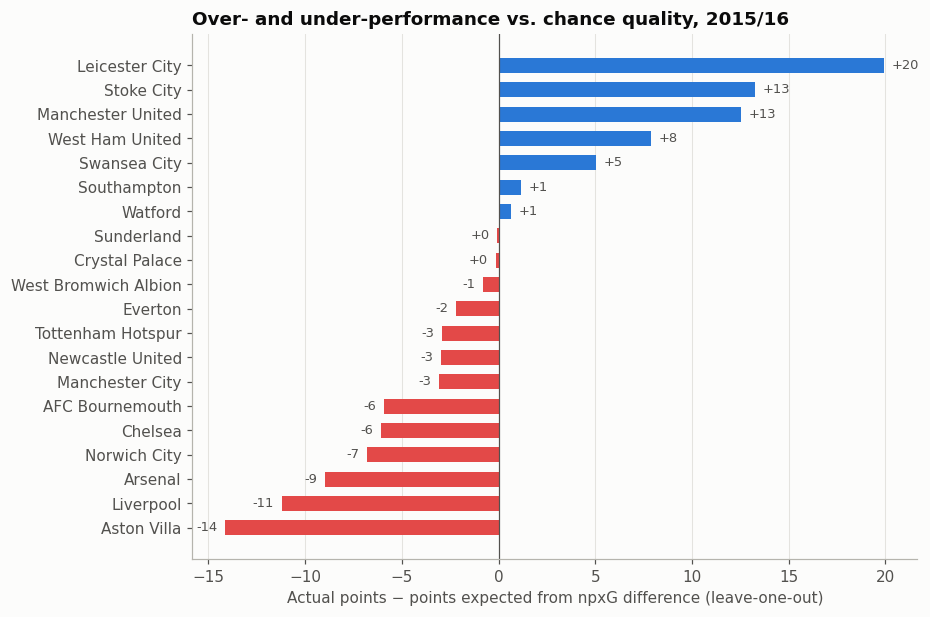

,team,points,expected_points,points_vs_expected,goals_for,npxg,goals_against,npxg_against
0,Leicester City,81,61.06,19.94,68,56.10,36,43.00
8,Stoke City,51,37.74,13.26,41,36.45,55,51.32
4,Manchester United,66,53.46,12.54,49,39.85,35,36.95
6,West Ham United,62,54.12,7.88,65,51.39,51,48.00
11,Swansea City,47,41.98,5.02,42,38.23,52,49.17
5,Southampton,63,61.85,1.15,59,51.09,41,38.97
12,Watford,45,44.35,0.65,40,38.60,50,47.14
16,Sunderland,39,39.08,-0.08,48,40.14,62,54.95
14,Crystal Palace,42,42.15,-0.15,39,38.47,51,49.67
13,West Bromwich Albion,43,43.82,-0.82,34,34.71,48,44.00


In [4]:
teams["expected_points"] = preds["npxg_diff"]
teams["points_vs_expected"] = teams["points"] - teams["expected_points"]
resid = teams.sort_values("points_vs_expected")

fig, ax = plt.subplots(figsize=(8.5, 6.2))
colors = np.where(resid["points_vs_expected"] >= 0, SERIES[0], SERIES[7])
ax.barh(resid["team"], resid["points_vs_expected"], color=colors, height=0.62)
ax.axvline(0, color=TEXT_SECONDARY, lw=0.8)
for y, v in enumerate(resid["points_vs_expected"]):
    ax.text(v + (0.4 if v >= 0 else -0.4), y, f"{round(v):+d}", va="center",
            ha="left" if v >= 0 else "right", fontsize=8.5, color=TEXT_SECONDARY)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Actual points − points expected from npxG difference (leave-one-out)")
ax.set_title("Over- and under-performance vs. chance quality, 2015/16")
save(fig, "team_points_vs_expected")
plt.show()
teams.sort_values("points_vs_expected", ascending=False)[
    ["team", "points", "expected_points", "points_vs_expected", "goals_for", "npxg", "goals_against", "npxg_against"]]

## Q3. Team styles

Two numbers summarise a team's relationship with the ball: how much threat it **creates** per match by moving the ball forward (xT for) and how much it **allows** (xT against).

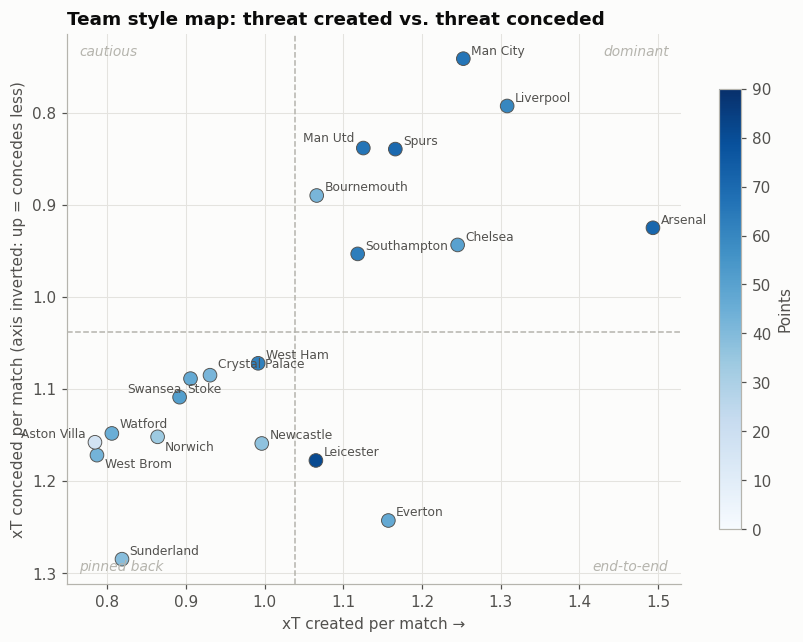

In [5]:
fig, ax = plt.subplots(figsize=(9, 6.5))
x, y = teams["xt_pm"], teams["xt_against_pm"]
ax.axvline(x.mean(), color=MUTED, lw=1, ls="--")
ax.axhline(y.mean(), color=MUTED, lw=1, ls="--")
sc = ax.scatter(x, y, c=teams["points"], cmap="Blues", vmin=0, vmax=90, s=80, edgecolor=TEXT_SECONDARY,
                linewidth=0.6, zorder=3)
label_points(ax, x, y, teams["short"], {
    "Man Utd": (-6, 4), "Crystal Palace": (5, 5), "Swansea": (-6, -9), "Watford": (5, 4),
    "Aston Villa": (-6, 3), "West Brom": (5, -8), "Norwich": (5, -9)})
ax.invert_yaxis()  # conceding less is better, so it goes up
ax.set_xlabel("xT created per match →")
ax.set_ylabel("xT conceded per match (axis inverted: up = concedes less)")
ax.set_title("Team style map: threat created vs. threat conceded")
fig.colorbar(sc, ax=ax, label="Points", shrink=0.8)
# Axes coordinates: y = 1 is the top of the plot, i.e. conceding least.
for tx, ty, txt in [(0.98, 0.98, "dominant"), (0.98, 0.02, "end-to-end"),
                    (0.02, 0.98, "cautious"), (0.02, 0.02, "pinned back")]:
    ax.text(tx, ty, txt, transform=ax.transAxes, ha="right" if tx > 0.5 else "left",
            va="top" if ty > 0.5 else "bottom", fontsize=9, color=MUTED, style="italic")
save(fig, "team_style_map")
plt.show()

### PCA of team style (descriptive)

PCA on nine per-match style metrics, to see whether the style map's two axes are the main dimensions of variation. With 20 teams this is descriptive only: the components summarise this season's teams and shouldn't be read as general laws.

In [6]:
STYLE = ["passes_pm", "pass_completion", "xt_pm", "xt_against_pm", "box_entries_pm",
         "final_third_entries_pm", "shots_pm", "xg_pm", "xg_against_pm"]
Z = StandardScaler().fit_transform(teams[STYLE])
pca = PCA().fit(Z)
team_scores = pca.transform(Z)
print("Explained variance:", np.round(pca.explained_variance_ratio_[:4], 3),
      "cumulative:", np.round(pca.explained_variance_ratio_[:4].cumsum(), 3))
loadings = pd.DataFrame(pca.components_[:3].T, index=STYLE, columns=["PC1", "PC2", "PC3"])
loadings.style.background_gradient(cmap=DIVERGING, vmin=-0.7, vmax=0.7).format("{:.2f}")

Explained variance: [0.759 0.132 0.052 0.026] cumulative: [0.759 0.891 0.943 0.969]


,PC1,PC2,PC3
passes_pm,0.35,-0.35,0.09
pass_completion,0.31,-0.46,0.27
xt_pm,0.36,0.10,0.28
xt_against_pm,-0.33,0.09,0.64
box_entries_pm,0.36,0.04,0.22
final_third_entries_pm,0.36,-0.30,0.03
shots_pm,0.31,0.44,0.07
xg_pm,0.28,0.58,0.24
xg_against_pm,-0.33,-0.18,0.56


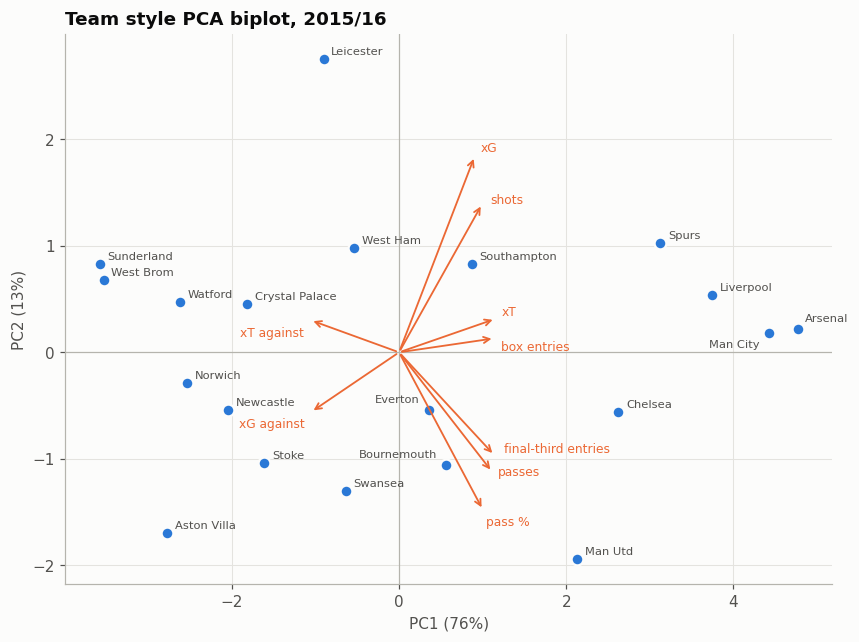

In [7]:
fig, ax = plt.subplots(figsize=(9, 6.5))
ax.scatter(team_scores[:, 0], team_scores[:, 1], s=60, color=SERIES[0], edgecolor=SURFACE, linewidth=1.5, zorder=3)
label_points(ax, team_scores[:, 0], team_scores[:, 1], teams["short"], fontsize=7.5,
             offsets={"Arsenal": (5, 5), "Man City": (-6, -10), "Bournemouth": (-6, 5), "Everton": (-6, 5)})
# Arrow labels: (name, dx, dy in points) chosen so near-parallel arrows stay readable.
ARROW_LABELS = {
    "passes_pm": ("passes", 4, -2), "pass_completion": ("pass %", 2, -10),
    "final_third_entries_pm": ("final-third entries", 6, 2), "xt_pm": ("xT", 4, 2),
    "box_entries_pm": ("box entries", 4, -8), "shots_pm": ("shots", 5, 0), "xg_pm": ("xG", 4, 3),
    "xt_against_pm": ("xT against", -4, -11), "xg_against_pm": ("xG against", -4, -10),
}
scale = 3.2
for feat, (lx, ly) in zip(STYLE, pca.components_[:2].T):
    tip = (lx * scale, ly * scale)
    ax.annotate("", xy=tip, xytext=(0, 0), arrowprops={"arrowstyle": "->", "color": SERIES[1], "lw": 1.2})
    name, dx, dy = ARROW_LABELS[feat]
    ax.annotate(name, tip, xytext=(dx, dy), textcoords="offset points", color=SERIES[1], fontsize=8,
                ha="right" if dx < 0 else "left")
ax.axhline(0, color=MUTED, lw=0.8)
ax.axvline(0, color=MUTED, lw=0.8)
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%})")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%})")
ax.set_title("Team style PCA biplot, 2015/16")
save(fig, "team_style_pca")
plt.show()

* **PC1, overall quality (76%).** Everything a good team does more of (passes, completion, xT, box entries, shots, xG) loads positively, and threat conceded loads negatively. It mostly rebuilds the league table.
* **PC2, direct vs. possession (13%).** Shots and xG load positively, passing volume and completion negatively. **Leicester** sit at the direct extreme, turning modest possession into a lot of shots. **Manchester United** (Louis van Gaal's final season, widely criticised for slow possession) sit at the opposite extreme, with plenty of the ball and few chances.

## Takeaways

1. **Chance quality explains the table.** npxG difference alone predicts a team's final points to within about 6 (LOO MAE 6.3, R² 0.70). Season xT difference is much weaker (R² 0.33) and adds nothing once npxG is known.
2. **Leicester beat their numbers by about 20 points**, the largest over-performance in the league. They finished on 81 points against roughly 61 expected from their chance quality, scoring 68 from 56 npxG and conceding 36 from 43 npxG against. Stoke and Manchester United also out-performed. Liverpool, Arsenal (the best npxG difference in the league) and Aston Villa under-performed.
3. **Leicester won the league with a negative xT difference.** Opponents moved the ball into dangerous areas against them more than they did themselves: Leicester conceded the 3rd-most xT in the league and were 18th of 20 in passes per match. This is the statistical signature of a deep, counter-attacking side. They gave up possession and territory but still created the 5th-best npxG, and they kept npxG conceded mid-table (8th-best) despite all that territory. xT measures *territory gained*, and in 2015/16 that was not the same as winning.

**Limitations.** n = 20 means even leave-one-out estimates are noisy: a single team (Leicester) moves the R² noticeably. Over- and under-performance against xG combines finishing skill, goalkeeping and luck, and one season cannot separate them.